# Player Feedback Analysis Using Unsupervised NLP

### Project Background

Omega Strikers was one of my favorite online multiplayer games, but its declining playerbase eventually made it difficult to find matches and continue playing.
As someone who enjoyed the game, I became curious about what other players thought went wrong. I decided to explore its Steam reviews using **unsupervised NLP and topic modeling**, both to identify recurring player complaints and to develop my practical machine learning skills.
This project combines my personal interest in gaming with my ongoing exploration of data science.

**Research question:** What recurring themes appear in negative *Omega Strikers* Steam reviews?

**Approach:** Steam review data → text preprocessing → TF-IDF → Non-negative Matrix Factorization (NMF) → qualitative topic interpretation → dominant-topic distribution. A separate exploratory section tests multi-topic assignments.

**Reproducibility:** Place `omega_strikers_reviews.csv` in the same folder as this notebook. Run cells from top to bottom. Required packages: `pandas`, `numpy`, `scikit-learn`, `matplotlib`, `ipython` (typically provided by Jupyter). The CSV is not embedded in this notebook.

> **Scope:** These are themes in a filtered sample of negative reviews, not verified rates of individual complaints across the game's entire playerbase. NMF weights are not probabilities.

## 1. Load and inspect the dataset
The input CSV contains reviews collected from Steam. Inspect missing values, duplicates, recommendation distribution, and date coverage before preprocessing.

In [3]:
import pandas as pd

df = pd.read_csv("omega_strikers_reviews.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (10000, 9)

Columns:
['review_id', 'review', 'recommended', 'date', 'playtime_hours', 'helpful_votes', 'funny_votes', 'steam_purchase', 'received_for_free']


,review_id,review,recommended,date,playtime_hours,helpful_votes,funny_votes,steam_purchase,received_for_free
0,237132042,"looks like fun, but ONLINE SEEMS D34D :X",True,2026-10-07,1.3,0,0,True,False
1,237084285,i guenuenly wish this game got as big as leagu...,True,2026-10-06,83.4,0,0,True,False
2,237018898,I mean its fun but you will spend more time wa...,True,2026-10-06,4.8,0,0,True,False
3,236860941,Watching what happened to Omega Strikers is so...,True,2026-10-04,38.2,1,1,True,False
4,236831187,top tier hockey moba. its actually really fun ...,True,2026-10-03,7.7,0,0,True,False


In [4]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate review IDs
print("\nDuplicate review IDs:")
print(df["review_id"].duplicated().sum())

# Check positive vs negative reviews
print("\nReview distribution:")
print(df["recommended"].value_counts())

# Check date coverage
print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())

Missing values:
review_id             0
review               15
recommended           0
date                  0
playtime_hours        0
helpful_votes         0
funny_votes           0
steam_purchase        0
received_for_free     0
dtype: int64

Duplicate review IDs:
0

Review distribution:
recommended
True     8400
False    1600
Name: count, dtype: int64

Date range:
2022-10-24 to 2026-10-07


## 2. Clean text and select negative reviews
Remove missing/empty review text and duplicate IDs, then normalize Steam markup, URLs, and punctuation. Retain the original review text for qualitative inspection. This English-oriented normalization discards numbers, emojis, and non-ASCII text, which can remove useful context.

In [5]:
import re

# Create a copy
df_clean = df.copy()

# Remove rows with missing review text
df_clean = df_clean.dropna(subset=["review"])

# Remove duplicate review IDs
df_clean = df_clean.drop_duplicates(subset=["review_id"])

# Clean text
def clean_text(text):
    text = text.lower()
    text = re.sub(r"\[/?[a-zA-Z][^\]]*\]", " ", text)  # Steam formatting tags
    text = re.sub(r"http\S+|www\.\S+", " ", text)       # URLs
    text = re.sub(r"[^a-z\s']", " ", text)              # Punctuation, numbers, emojis
    text = re.sub(r"\s+", " ", text)                    # Extra spaces
    return text.strip()

df_clean["clean_review"] = df_clean["review"].apply(clean_text)

# Remove reviews that became empty after cleaning
df_clean = df_clean[df_clean["clean_review"] != ""].copy()

print("Original reviews:", len(df))
print("Cleaned reviews:", len(df_clean))

display(df_clean[["review", "clean_review"]].head(10))

Original reviews: 10000
Cleaned reviews: 9844


,review,clean_review
0,"looks like fun, but ONLINE SEEMS D34D :X",looks like fun but online seems d d x
1,i guenuenly wish this game got as big as leagu...,i guenuenly wish this game got as big as league
2,I mean its fun but you will spend more time wa...,i mean its fun but you will spend more time wa...
3,Watching what happened to Omega Strikers is so...,watching what happened to omega strikers is so...
4,top tier hockey moba. its actually really fun ...,top tier hockey moba its actually really fun b...
5,I love being goalie as Juliette,i love being goalie as juliette
7,literally the worst community of people ive ev...,literally the worst community of people ive ev...
8,Probably one of the biggest upsets for me pers...,probably one of the biggest upsets for me pers...
9,dead but gold. so unfortunate,dead but gold so unfortunate
10,No.,no


In [6]:
#Isolate negative reviews
df_negative = df_clean[
    df_clean["recommended"] == False
].copy()

print("Negative reviews:", len(df_negative))

display(df_negative[["clean_review", "recommended"]].head(10))

Negative reviews: 1585


,clean_review,recommended
7,literally the worst community of people ive ev...,False
10,no,False
17,the second you queue into a game you get bruta...,False
22,negative review,False
25,i wanted to give this game a chance as it seem...,False
26,lots of fun as a multiplayer air hockey game v...,False
29,omega strikers is a gifted game self marched t...,False
30,i loved the beta played it at my friends tried...,False
39,modern day retelling of the myth of icarus sha...,False
41,the privacy policy states that it collects you...,False


## 3. Baseline NMF on all negative reviews
Vectorize the text with TF-IDF (unigrams and bigrams), then fit an eight-topic NMF model. Eight is an exploratory choice, not an optimized topic count. Examine top words and representative reviews to interpret the themes.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

# converting the negative reviews into TF-IDF numbers
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_df=0.90,
    min_df=3,
    ngram_range=(1, 2)
)

X = vectorizer.fit_transform(df_negative["clean_review"])

print("TF-IDF matrix shape:", X.shape)

TF-IDF matrix shape: (1585, 3821)


In [8]:
from sklearn.decomposition import NMF

# Clustering using NMF
nmf = NMF(
    n_components=8,
    random_state=42,
    init="nndsvda",
    max_iter=500
)

W = nmf.fit_transform(X)

print("Review-topic matrix:", W.shape)
print("Topic-term matrix:", nmf.components_.shape)

feature_names = vectorizer.get_feature_names_out()

for topic_idx, topic in enumerate(nmf.components_):
    top_indices = topic.argsort()[-12:][::-1]
    top_words = feature_names[top_indices]

    print(f"Topic {topic_idx}: {', '.join(top_words)}")

Review-topic matrix: (1585, 8)
Topic-term matrix: (8, 3821)
Topic 0: game, great, ass, great game, devs, trash, hate, ruined, garbage, dog, fun game, game game
Topic 1: dead, dead game, game dead, fun dead, game, fun, playing, queue, game playing, hell, lmfao, tryhards
Topic 2: bad, bad game, game bad, matchmaking, bad matchmaking, really bad, takes, really, ranking, matchmaking bad, goalie, stuff
Topic 3: just, fun, players, match, new, time, team, really, games, matchmaking, playing, player
Topic 4: beta, better, beta better, better beta, game better, sucks, release, revert, changes, game beta, used, lmao
Topic 5: like, league, like game, game like, legends, feels, dont like, league legends, don like, dont, don, feels like
Topic 6: play, play game, don, want, don play, want play, people, characters, friends, game play, dont, people play
Topic 7: good, good game, game good, used, fun game, just good, good team, good luck, anymore, luck, team, idiot


In [9]:
import numpy as np

for topic_id in range(8):
    print(f"\n{'='*60}")
    print(f"TOPIC {topic_id}")
    print(f"{'='*60}")

    # Find the 3 reviews with the highest weight for this topic
    top_review_indices = np.argsort(W[:, topic_id])[-3:][::-1]

    for idx in top_review_indices:
        review = df_negative.iloc[idx]["review"]

        print(f"\nScore: {W[idx, topic_id]:.4f}")
        print(review[:800])
        print("-" * 40)


TOPIC 0

Score: 0.3575
this game has consumed me
----------------------------------------

Score: 0.3575
This game is no bueno
----------------------------------------

Score: 0.3575
♥♥♥♥ this game
----------------------------------------

TOPIC 1

Score: 0.4334
Dead game.
----------------------------------------

Score: 0.4334
dead game
----------------------------------------

Score: 0.4334
dead game
----------------------------------------

TOPIC 2

Score: 0.4845
bad
----------------------------------------

Score: 0.4845
bad
----------------------------------------

Score: 0.4845
bad
----------------------------------------

TOPIC 3

Score: 0.1313
Overall I think this game is really fun! But it's got a few big flaws that I think can really hurt someone's motivation to play it. So despite the fact that I enjoy the core game and can overlook these problems myself, I'm leaving a negative in hopes that these flaws can get patched up.

- Cannot permanently/globally mute emotes
This is 

### Baseline observations (qualitative)

- **Topic 0:** Generic dissatisfaction; not a specific complaint.
- **Topic 1:** Low player activity / “dead game.”
- **Topic 2:** Generic negative evaluations.
- **Topic 3:** Broad gameplay commentary and mixed complaints.
- **Topic 4:** Beta vs. full-release changes.
- **Topic 5:** Mixed/uninformative remarks, including jokes.
- **Topic 6:** Broad rejection and miscellaneous comments.
- **Topic 7:** Generic “good/not good” evaluations.

**Interpretation:** Short reviews such as “bad” or “dead game” can dominate TF-IDF features. These preliminary labels describe inspected examples, not validated categories.

## 4. Filter short reviews and retrain
Keep reviews with at least **10 cleaned words** to reduce single-word topics. This is a pragmatic cutoff, not a standard NLP rule; it excludes some concise but informative complaints. Compare the topic keywords and representative reviews with the baseline.

In [10]:
# Count words in each cleaned review
df_negative["word_count"] = (
    df_negative["clean_review"].str.split().str.len()
)

# Check how many reviews we'd retain
print("All negative reviews:", len(df_negative))

print(
    "Reviews with 10+ words:",
    (df_negative["word_count"] >= 10).sum()
)

print(
    "Reviews with fewer than 10 words:",
    (df_negative["word_count"] < 10).sum()
)

All negative reviews: 1585
Reviews with 10+ words: 1088
Reviews with fewer than 10 words: 497


In [11]:
# Keep reviews with at least 10 words
df_topics = df_negative[
    df_negative["word_count"] >= 10
].copy()

# Refit TF-IDF
X_topics = vectorizer.fit_transform(
    df_topics["clean_review"]
)

# Retrain NMF
W_topics = nmf.fit_transform(X_topics)

print("Reviews:", len(df_topics))
print("TF-IDF shape:", X_topics.shape)
print("NMF shape:", W_topics.shape)

feature_names = vectorizer.get_feature_names_out()

for topic_idx, topic in enumerate(nmf.components_):
    top_indices = topic.argsort()[-12:][::-1]
    top_words = feature_names[top_indices]

    print(f"Topic {topic_idx}: {', '.join(top_words)}")

Reviews: 1088
TF-IDF shape: (1088, 3738)
NMF shape: (1088, 8)
Topic 0: just, like, team, character, really, match, feel, game, characters, feels, goalie, way
Topic 1: beta, release, changes, game, rng, played, great, game beta, long, way, better, new
Topic 2: game, dead, bad, time, devs, good, queue, good game, dead game, people, game dead, worst
Topic 3: players, new, matchmaking, player, new players, new player, team, terrible, matched, experience, rank, games
Topic 4: play, play game, game, want, want play, people, friends, don, people play, don play, servers, dont
Topic 5: fun, fun game, game fun, games, really, kinda, game, used fun, really fun, fun play, fun time, core
Topic 6: strikers, omega, omega strikers, gameplay, game, competitive, balance, odyssey, games, interactive, review, ruin
Topic 7: league, legends, league legends, hate, rocket, rocket league, hate game, like, like league, game, people, want


In [12]:
for topic_id in range(nmf.n_components):
    print(f"\n{'='*60}")
    print(f"TOPIC {topic_id}")
    print(f"{'='*60}")

    top_indices = np.argsort(W_topics[:, topic_id])[-3:][::-1]

    for idx in top_indices:
        review = df_topics.iloc[idx]["review"]

        print(f"\nTopic weight: {W_topics[idx, topic_id]:.4f}")
        print(review[:1000])
        print("-" * 40)


TOPIC 0

Topic weight: 0.2082
[h1] LET THIS BE A WARNING FOR THOSE WHO WANT TO PLAY THIS GAME [/h1]
(13/06/2023)

I hate that I both like this game and also despise it. It is so bare bones and so ♥♥♥♥♥♥ with its meta and balancing that I want to pluck my hair out. The characters are really not that interesting and game(just before this update) did not even disband lobby, if someone left DURING MATCHMAKING. Imagine demoting because of a jackass who left game because "my fav character got banned ;-;". 

[hr][/hr]

[u][b] Matchmaking [/b][/u]
Matchmaking has way more flaws than just not disbanding. You WILL be matched with people who are better than you, ON YOUR FIRST MATCH. Like what kind of ♥♥♥♥ up torture is this? Imagine playing first time against people who know the game. So much fun getting your ass handed. 

Even thought the game has AI mode you cannot switch to it before you complete downright moronic quests that lock ♥♥♥♥ all(Seriously I can't open the shop to look at stuff or c

### Length-filtered model observations

- **Topic 0:** General gameplay discussion (unclear).
- **Topic 1:** Beta vs. full release.
- **Topic 2:** Declining playerbase / queue times.
- **Topic 3:** Matchmaking and new-player skill disparities.
- **Topic 4:** Playing with friends / access (mixed).
- **Topic 5:** Enjoyment and mixed sentiment.
- **Topic 6:** Broad gameplay design and balance (mixed).
- **Topic 7:** Comparisons with other multiplayer games.

Several themes became clearer, but generic words such as “game,” “play,” and “fun” still dominate some topics.

## 5. Remove duplicate review text
Normalize text for exact duplicate detection and remove repeated reviews **before the final model fit**. This avoids training the final NMF model twice and prevents duplicated phrasing from over-weighting topics.

In [13]:
# Normalize review text for duplicate detection
df_topics["review_normalized"] = (
    df_topics["clean_review"]
    .str.lower()
    .str.replace(r"[^a-z0-9\s]", "", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Identify duplicates, keeping the first occurrence
duplicates = df_topics[
    df_topics.duplicated(
        subset=["review_normalized"],
        keep="first"
    )
]

print("Total reviews:", len(df_topics))
print("Duplicate reviews:", len(duplicates))
print("Unique reviews:", len(df_topics) - len(duplicates))

display(duplicates[["review", "review_normalized"]].head(10))

Total reviews: 1088
Duplicate reviews: 3
Unique reviews: 1085


,review,review_normalized
7479,"I wish I could recommend this game, because it...",i wish i could recommend this game because it ...
7791,Finding a cool and unique game that is actuall...,finding a cool and unique game that is actuall...
9976,Game would be great if the matchmaking wouldn'...,game would be great if the matchmaking wouldnt...


In [14]:
# Deduplicate the length-filtered reviews before fitting the final model.
df_topics = (
    df_topics.drop_duplicates(subset=["review_normalized"], keep="first")
    .reset_index(drop=True)
)
print("Unique reviews for final topic modeling:", len(df_topics))

Unique reviews for final topic modeling: 1085


## 6. Improved NMF (V2): domain-specific stopwords
Remove common game-review terms to encourage more specific themes. These choices are experimental: dropping terms like “fun” may hide some genuine enjoyment-related complaints. Inspect top terms and representative reviews after fitting.

In [15]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS


custom_stopwords = ENGLISH_STOP_WORDS.union({
    "game",
    "games",
    "omega",
    "strikers",
    "play",
    "playing",
    "played",
    "fun",
    "good",
    "bad",
    "just",
    "really",
    "like"
})

vectorizer_v2 = TfidfVectorizer(
    stop_words=list(custom_stopwords),
    max_df=0.90,
    min_df=3,
    ngram_range=(1, 2)
)

X_topics_v2 = vectorizer_v2.fit_transform(
    df_topics["clean_review"]
)

nmf_v2 = NMF(
    n_components=8,
    random_state=42,
    init="nndsvda",
    max_iter=500
)

W_topics_v2 = nmf_v2.fit_transform(X_topics_v2)

feature_names_v2 = vectorizer_v2.get_feature_names_out()

for topic_idx, topic in enumerate(nmf_v2.components_):
    top_indices = topic.argsort()[-12:][::-1]
    top_words = feature_names_v2[top_indices]

    print(f"Topic {topic_idx}: {', '.join(top_words)}")

Topic 0: characters, character, feel, don, feels, way, match, gameplay, competitive, make, people, matches
Topic 1: beta, release, changes, long, better, great, rng, way, make, better beta, longer, feels
Topic 2: dead, match, queue, servers, minutes, matches, people, long, unfortunately, pretty, takes, pretty dead
Topic 3: players, new, player, new players, new player, try, matched, learn, toxic, got, losing, hours
Topic 4: league, legends, league legends, hate, rocket, rocket league, want, people, moba, literally, boring, im
Topic 5: time, waste, waste time, don, worth, bother, don bother, worth time, don waste, time don, dont, lol
Topic 6: team, enemy, enemy team, chat, teammates, afk, goal, goalie, leave, report, people, quit
Topic 7: matchmaking, terrible, ass, great, fix, getting, people, terrible matchmaking, matchmaking terrible, want, great matchmaking, dont


In [16]:
for topic_id in range(nmf_v2.n_components):
    print(f"\n{'='*60}")
    print(f"TOPIC {topic_id}")
    print(f"{'='*60}")

    # Get the 3 reviews with the highest weight for this topic
    top_indices = np.argsort(W_topics_v2[:, topic_id])[-3:][::-1]

    for idx in top_indices:
        review = df_topics.iloc[idx]["review"]

        print(f"\nTopic weight: {W_topics_v2[idx, topic_id]:.4f}")
        print(review[:1000])
        print("-" * 40)


TOPIC 0

Topic weight: 0.1882
I want to enjoy this game, and I will keep playing it, however a few things are keeping me from recommending this game.
Firstly is the matchmaking, my god its not even funny how unbalanced it feels at times with the way teams are stacked up, do yourself a favor and avoid normal mode like the plague until you have at least 30-50 hours in the game. The mode itself is comp but you don't have a ban phase, which sounds fine but the matches take much longer then quick play, give slightly better rewards (if you win) and overall feel helpless if your getting stomped (which as a new player you absolutely will be).
I feel this problem is due to a lack of newer players coming in, and veterans having so much more experience that they can exploit often overlooked mechanics and abilities, sure with time you can get the hang of this, but if I wanted to get stomped playing a Moba I would go back to league...

Secondly, the balancing... Now let me preface this point by sa

### Final-model topic interpretations (qualitative)

- **Topic 0: General Gameplay Criticism:** Broad criticism of gameplay and characters.
- **Topic 1: Beta vs. Full Release:** Dissatisfaction with changes since beta.
- **Topic 2: Declining Playerbase:** Low activity and long queues.
- **Topic 3: New-Player Experience:** Skill disparities and onboarding issues.
- **Topic 4: Competitor Comparisons:** Comparisons with other multiplayer games.
- **Topic 5: Perceived Waste of Time:** Low enjoyment and frustration with time invested.
- **Topic 6: Team Performance:** Teammates, communication, and team imbalance.
- **Topic 7: General Matchmaking:** Broad matchmaking dissatisfaction.

**Assessment:** Several themes are interpretable, while Topic 0 remains broad and Topics 3/7 overlap. Topic IDs refer to this specific fitted model and may change on retraining. Labels are analyst interpretations, not supervised ground truth.

## 7. Dominant-topic distribution
Assign each review to its highest-weighted NMF topic for a simple, mutually exclusive summary. These counts represent **model-assigned dominant topics**, not the percentage of reviews that explicitly mention each complaint.

In [17]:
# Assign each review its highest-weighted topic
df_topics["dominant_topic"] = np.argmax(
    W_topics_v2,
    axis=1
)

topic_names = {
    0: "General Gameplay Criticism",
    1: "Beta vs. Full Release",
    2: "Declining Playerbase",
    3: "New-Player Experience",
    4: "Competitor Comparisons",
    5: "Perceived Waste of Time",
    6: "Team Performance",
    7: "General Matchmaking"
}

df_topics["topic_name"] = df_topics["dominant_topic"].map(topic_names)

topic_distribution = (
    df_topics["topic_name"]
    .value_counts()
    .rename_axis("Topic")
    .reset_index(name="Reviews")
)

topic_distribution["Percentage"] = (
    topic_distribution["Reviews"] / len(df_topics) * 100
).round(2)

display(topic_distribution)

,Topic,Reviews,Percentage
0,General Gameplay Criticism,275,25.35
1,Team Performance,148,13.64
2,New-Player Experience,142,13.09
3,Beta vs. Full Release,134,12.35
4,Declining Playerbase,117,10.78
5,General Matchmaking,115,10.60
6,Perceived Waste of Time,95,8.76
7,Competitor Comparisons,59,5.44


## 8. Exploratory multi-topic analysis
NMF gives each review a weight for every topic. Test whether a review can receive multiple topic associations using a relative cutoff plus an absolute minimum. These cutoffs are heuristic; they are **not** calibrated confidence or probability thresholds.

In [18]:
# Get the highest topic weight for each review
max_weights = W_topics_v2.max(axis=1, keepdims=True)

# Assign topics with at least 50% of the highest weight
# Also require a minimum absolute weight to avoid very weak matches
threshold = 0.50
min_weight = 0.03

multi_topic_mask = (
    (W_topics_v2 >= max_weights * threshold)
    & (W_topics_v2 >= min_weight)
)

# Convert qualifying topics into lists
df_topics["multi_topics"] = [
    np.where(row)[0].tolist()
    for row in multi_topic_mask
]

# Count topics assigned to each review
df_topics["topic_count"] = df_topics["multi_topics"].apply(len)

print("Reviews with no assigned topics:",
      (df_topics["topic_count"] == 0).sum())

print("\nNumber of topics assigned per review:")
print(df_topics["topic_count"].value_counts().sort_index())

display(
    df_topics[
        ["clean_review", "dominant_topic", "multi_topics", "topic_count"]
    ].head(10)
)

Reviews with no assigned topics: 116

Number of topics assigned per review:
topic_count
0    116
1    572
2    280
3     93
4     21
5      2
6      1
Name: count, dtype: int64


,clean_review,dominant_topic,multi_topics,topic_count
0,literally the worst community of people ive ev...,7,"[2, 4, 6, 7]",4
1,the second you queue into a game you get bruta...,2,[2],1
2,i wanted to give this game a chance as it seem...,3,"[2, 3]",2
3,lots of fun as a multiplayer air hockey game v...,0,[0],1
4,omega strikers is a gifted game self marched t...,6,[],0
5,i loved the beta played it at my friends tried...,1,"[1, 4]",2
6,modern day retelling of the myth of icarus sha...,0,[0],1
7,the privacy policy states that it collects you...,0,[],0
8,i want to like this game so bad but it's ass p...,7,[7],1
9,i would rather get roofied by bill cosby than ...,0,[],0


In [19]:
# Reviews assigned to 3 or more topics
multi_sample = df_topics[
    df_topics["topic_count"] >= 3
].sample(5, random_state=42)

# Reviews assigned to zero topics
zero_sample = df_topics[
    df_topics["topic_count"] == 0
].sample(5, random_state=42)

# Print full reviews and assigned topics
for title, sample in [
    ("MULTIPLE TOPICS", multi_sample),
    ("NO TOPICS", zero_sample)
]:
    print(f"\n{'='*60}")
    print(title)
    print('='*60)

    for _, row in sample.iterrows():
        print("\nReview:", row["review"])
        print("Dominant topic:", row["dominant_topic"])
        print("Assigned topics:", row["multi_topics"])
        print("-"*40)


MULTIPLE TOPICS

Review: lack of players. too long queue time 10 to 20 mins per game.
Dominant topic: 3
Assigned topics: [2, 3, 5]
----------------------------------------

Review: im really torn on this review because this game absolutley consumed my life when it came out. it was perfect. zero bugs, good frames, smooth and addictive yet simple gameplay and most importantly a fantastic development studio. i cant commend them enough however after about a year it got the ol' yeller treatment and got taken out back. This game had HUGE potential but unfortunatly just didnt gain traction. i recently went back to it a few months ago and tried to find a match but struggled and the one match i found ended up having people quit.

ill support this dev team to the moon and back and seeing this in my library made me feel a little nostalgic.  i look foreword to their other projects theyve mentioned theyve got in the works but simply put youll take longer finding a match in most situations then act

### Threshold sensitivity
Compare four threshold combinations without refitting NMF. More multi-topic assignments do not imply greater accuracy. The review inspection revealed both spurious assignments and missed complaints, including technical issues not captured by a dedicated topic.

In [20]:
# Threshold combinations to test
settings = [
    (0.50, 0.03),  # Current
    (0.70, 0.03),  # Stricter
    (0.50, 0.01),  # More permissive
    (0.70, 0.01)
]

results = []

for threshold, min_weight in settings:

    max_weights = W_topics_v2.max(axis=1, keepdims=True)

    multi_topic_mask = (
        (W_topics_v2 >= max_weights * threshold)
        & (W_topics_v2 >= min_weight)
    )

    review_topic_counts = multi_topic_mask.sum(axis=1)

    results.append({
        "Relative Threshold": threshold,
        "Minimum Weight": min_weight,
        "Zero Topics": (review_topic_counts == 0).sum(),
        "One Topic": (review_topic_counts == 1).sum(),
        "Multiple Topics": (review_topic_counts >= 2).sum(),
        "Average Topics": round(review_topic_counts.mean(), 2)
    })

comparison_df = pd.DataFrame(results)

display(comparison_df)

,Relative Threshold,Minimum Weight,Zero Topics,One Topic,Multiple Topics,Average Topics
0,0.5,0.03,116,572,397,1.39
1,0.7,0.03,116,725,244,1.16
2,0.5,0.01,14,544,527,1.69
3,0.7,0.01,14,759,312,1.34


In [21]:
# New experimental thresholds
threshold = 0.70
min_weight = 0.01

max_weights = W_topics_v2.max(axis=1, keepdims=True)

multi_topic_mask = (
    (W_topics_v2 >= max_weights * threshold)
    & (W_topics_v2 >= min_weight)
)

# Save new assignments in separate columns
df_topics["multi_topics_v2"] = [
    np.where(row)[0].tolist()
    for row in multi_topic_mask
]

df_topics["topic_count_v2"] = (
    df_topics["multi_topics_v2"].apply(len)
)

# Compare old vs new assignments
display(
    df_topics[
        [
            "review",
            "multi_topics",
            "multi_topics_v2"
        ]
    ].sample(10, random_state=42)
)

,review,multi_topics,multi_topics_v2
749,Game is unsustainable in its current form and ...,"[2, 5]",[2]
56,Dead game with no player\n\nImagine waiting ha...,[2],[2]
937,breaks my heart to see what they did to this g...,[1],[1]
270,"Doesn't seem very balanced, games seem to be r...",[5],[5]
208,Not beginner friendly. Planning to play with f...,[3],[3]
86,game is fun but pretty dead i can't find a mat...,[2],[2]
713,"The game was exceptional prior to launch, but ...",[0],[0]
526,"Dont waste your time downloading this game, th...","[5, 7]","[5, 7]"
308,"Fun game, but constant balance patches give...","[0, 2, 3, 4, 7]","[3, 4, 7]"
323,This game has potential but is ruined by the d...,[3],[3]


In [22]:
# Find reviews where old and new assignments differ
changed_reviews = df_topics[
    df_topics["multi_topics"].apply(tuple)
    != df_topics["multi_topics_v2"].apply(tuple)
]

print("Reviews with changed assignments:", len(changed_reviews))

# Inspect 5 examples
for _, row in changed_reviews.sample(
    min(5, len(changed_reviews)),
    random_state=42
).iterrows():

    print("\n" + "=" * 60)
    print("REVIEW:")
    print(row["review"])

    print("\nOLD:", [
        topic_names[t] for t in row["multi_topics"]
    ])

    print("NEW:", [
        topic_names[t] for t in row["multi_topics_v2"]
    ])

Reviews with changed assignments: 331

REVIEW:
unskipple tutorial with bugs that wouldn't even let me finish it.

OLD: []
NEW: ['General Matchmaking']

REVIEW:
If your goalie sucks, time to be the better goalie. The game is great, overall. Especially with the amount of bad goalie screwing you over.

Edits:
I cannot recommend this game anymore. The game has been too stressful to play, and recent maps make it even more stressful. I remember the time X used to be painful to fight against but since he's nerfed, he cannot kill too easily. However, characters that are better at killing have popped up and at this point, this game is all about whether you can play or remain dead.

I would have loved that the game didn't have characters that can kill easily and that the maps weren't annoying as heck.

OLD: ['General Gameplay Criticism', 'Declining Playerbase', 'Perceived Waste of Time']
NEW: ['General Gameplay Criticism', 'Perceived Waste of Time']

REVIEW:
This game was killed by 3 factors 
1 

### Interpretation of multi-topic experiments

The initial `(0.50, 0.03)` and alternative `(0.70, 0.01)` cutoffs produced different assignments. Spot checks found cases where lowering the minimum weight introduced incorrect topics (for example, technical/tutorial issues being associated with matchmaking), while stricter relative thresholds sometimes removed valid secondary themes. **No threshold was validated as optimal.** Therefore, multi-topic counts are presented as exploratory sensitivity analysis, not as the primary complaint-frequency result.

## 9. Final visualization
Visualize the dominant-topic distribution for the deduplicated, length-filtered negative-review subset. This is the primary descriptive result.

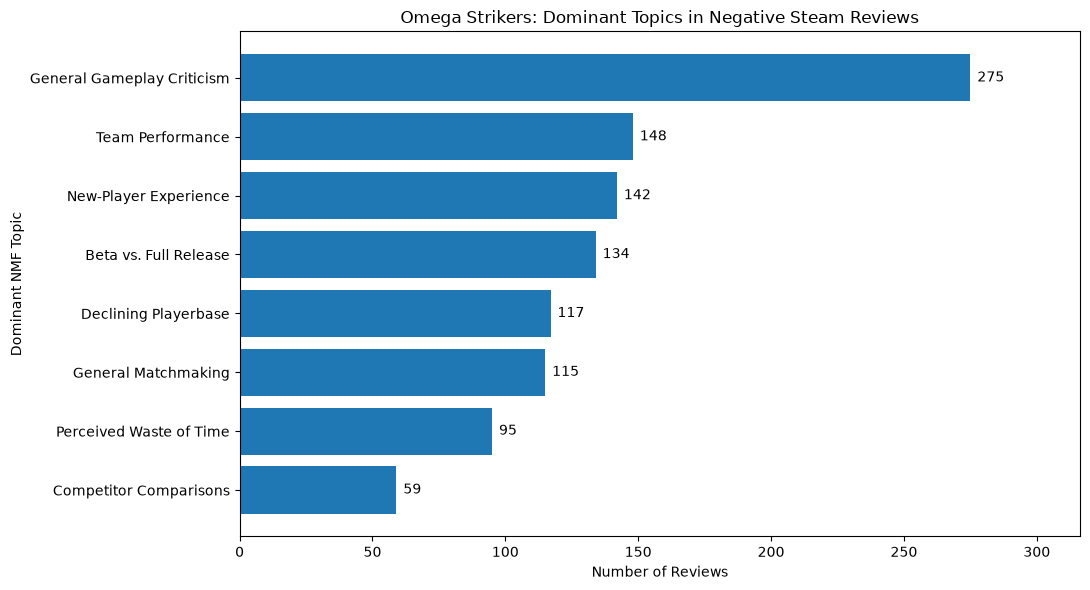

In [23]:
import matplotlib.pyplot as plt

plot_data = topic_distribution.sort_values("Reviews", ascending=True)

plt.figure(figsize=(11, 6))
bars = plt.barh(plot_data["Topic"], plot_data["Reviews"])
plt.bar_label(bars, padding=5)
plt.xlabel("Number of Reviews")
plt.ylabel("Dominant NMF Topic")
plt.title("Omega Strikers: Dominant Topics in Negative Steam Reviews")
plt.xlim(0, plot_data["Reviews"].max() * 1.15)
plt.tight_layout()
plt.show()

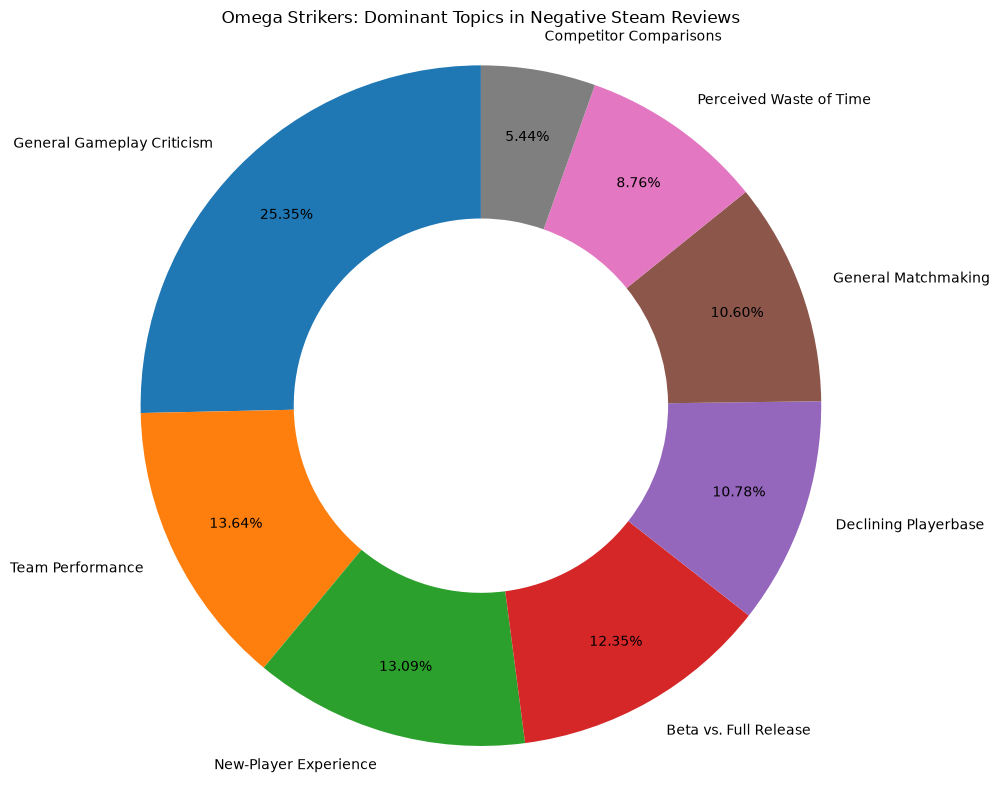

In [27]:
plt.figure(figsize=(10, 8))

plt.pie(
    topic_distribution["Reviews"],
    labels=topic_distribution["Topic"],
    autopct="%1.2f%%",
    startangle=90,
    pctdistance=0.80,
    wedgeprops={"width": 0.45}
)

plt.title("Omega Strikers: Dominant Topics in Negative Steam Reviews")

plt.axis("equal")
plt.tight_layout()
plt.show()

## 10. Findings and limitations

**Findings (from the original notebook run):** Among **1,085** unique negative reviews containing at least 10 cleaned words, the most common *dominant* NMF topic was **General Gameplay Criticism (275; 25.35%)**, followed by **Team Performance (148; 13.64%)**, **New-Player Experience (142; 13.09%)**, and **Beta vs. Full Release (134; 12.35%)**. Other recognizable themes include declining player activity and matchmaking dissatisfaction. These figures should be checked against the live output if the source CSV or environment changes.

**Limitations:**
- The original collection used Steam's `recent` review filter; this is **not a random sample** of all Steam reviews.
- The model analyzes a filtered subset of negative reviews. Short reviews and some cleaned-out texts were excluded.
- Topic labels come from qualitative inspection of keywords and a few representative reviews, **not systematic human validation**.
- Long reviews can discuss multiple issues; dominant-topic counts obscure those secondary themes.
- NMF weights reflect text-pattern associations, not probabilities. Multi-topic assignments proved sensitive to arbitrary thresholds.
- Some complaints (for example, bugs and loading issues) were not cleanly represented by the eight topics.

**Conclusion:** TF-IDF and NMF provided a useful exploratory overview of recurring negative-review themes, while qualitative checks highlighted the importance of cautious interpretation. A future improvement would be human validation of a representative review sample and comparison with alternative topic counts or methods.